# Module 03: Centralized vs. Federated Learning for 10-Cycle-Ahead SOH Forecasting

This notebook continues `01_soh_forecasting_and_degradation_risk.ipynb`. Notebook 01
trains every model on battery data pooled in one place. Here we ask whether a fleet of
batteries could train a comparable SOH forecaster **without sharing raw battery data**,
and whether **personalization** helps.

**Research question:** *Can federated learning forecast SOH 10 cycles ahead nearly as
accurately as centralized learning while each battery's raw cycle data stays local, and
does a personalized model (FedPer) beat a single shared model (FedAvg)?*

## What is compared

| Setting | Model | Raw data leaves the battery? | Personalized? |
|---|---|---|---|
| Naive reference | Persistence, SOH(t+10) = SOH(t) | n/a | n/a |
| Centralized | XGBoost (same settings as notebook 01) | Yes | No |
| Centralized | MLP (same network as the federated models) | Yes | No |
| Local only | One MLP per battery, no collaboration | No | Fully local |
| Federated | FedAvg (McMahan et al., 2017) | No | No |
| Federated | FedProx (Li et al., 2020) | No | No |
| Federated | FedPer (Arivazhagan et al., 2019) | No | Yes (local head) |

## Clients

Each **battery** is one federated client. This is a real federated setting: the 105
training batteries cover different chemistries (LFP, NMC, lab cells), charging types and
vehicles, so client data is genuinely heterogeneous (non-IID). This is a stronger setup
than Module 1, where every client was a trip from the same car.

## Data split

The split is identical to notebook 01, so all results are comparable:

- **Chronological test set:** for every battery, the last 20% of its cycles (3,652 rows).
  Every model is scored on exactly these rows.
- **Independent test set:** the 6 batteries in `data_test` that are never used for
  training. For federated learning these are **new clients joining the fleet**.

Inside the training part, the last 15% of each battery's training cycles is kept as a
local **validation** set. It is used only to choose the training length (epochs or
communication rounds). The test sets are never used to choose anything.

## Why a neural network for the federated models

FedAvg, FedProx and FedPer average model **weights**, which needs a gradient-trained
model. Gradient-boosted trees such as XGBoost cannot be averaged this way. So the
federated models use a small MLP, and we also train **the same MLP centrally**. This
separates two effects:

- **model-class gap:** centralized XGBoost vs. centralized MLP
- **federation gap:** centralized MLP vs. FedAvg / FedProx / FedPer

The MLP predicts the **change** in SOH over the next 10 cycles,
`SOH(t+10) - SOH(t)`, and the forecast is `SOH(t) + predicted change`. All MLP variants
(centralized, local, federated) use exactly this setup, so the comparison between them
is fair. Results are always reported on the SOH scale.

## 1. Setup

In [1]:
import os
import re
import glob
import copy
import time
import warnings

import numpy as np
import pandas as pd
from xgboost import XGBRegressor  # import before torch: the other order crashes XGBoost on macOS
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
# One thread is enough for these small networks, and it avoids an OpenMP clash
# between PyTorch and XGBoost on macOS that freezes the kernel.
torch.set_num_threads(1)

# Same data folders as notebook 01. Outside Colab, set SPARKEV_M3_DATA to the
# folder that contains data_train/ and data_test/.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

data_path = os.environ.get(
    'SPARKEV_M3_DATA',
    '/content/drive/MyDrive/EV_Battery_Project/data'
)
train_path = os.path.join(data_path, 'data_train')
test_path = os.path.join(data_path, 'data_test')

feature_files_train = sorted(glob.glob(os.path.join(train_path, '*.xlsx')))
feature_files_test = sorted(glob.glob(os.path.join(test_path, '*.xlsx')))
print("Training files:", len(feature_files_train))
print("Independent test files:", len(feature_files_test))

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7", "#e34948"]

Training files: 148
Independent test files: 6


## 2. Data pipeline (same as notebook 01)

The loading, feature engineering, target, feature filtering, chronological split and
preprocessing below reproduce notebook 01 step by step. The checks at the end confirm
the same row and feature counts as notebook 01.

In [2]:
def extract_file_metadata(filepath):
    filename = os.path.basename(filepath)
    stem = os.path.splitext(filename)[0]
    if re.search(r'_fast_feature$', stem, re.IGNORECASE):
        charge_type = 'fast'
    elif re.search(r'_slow_feature$', stem, re.IGNORECASE):
        charge_type = 'slow'
    else:
        charge_type = 'unknown'
    battery_id = re.sub(r'_(fast|slow)_feature$', '', stem, flags=re.IGNORECASE)
    if battery_id.upper().startswith('LFP'):
        battery_type = 'LFP'
    elif battery_id.upper().startswith('NMC'):
        battery_type = 'NMC'
    elif battery_id.upper().startswith('LAB'):
        battery_type = 'Unknown'
    else:
        battery_type = battery_id.split('_')[0]
    return {'source_file': filename, 'battery_id': battery_id,
            'battery_type': battery_type, 'charge_type': charge_type}


def load_files(files):
    frames = []
    for filepath in files:
        frame = pd.read_excel(filepath)
        for key, value in extract_file_metadata(filepath).items():
            frame[key] = value
        frames.append(frame)
    return pd.concat(frames, ignore_index=True)


def rolling_slope(values):
    values = np.asarray(values, dtype=float)
    if np.isnan(values).any() or len(values) < 2:
        return np.nan
    return np.polyfit(np.arange(len(values)), values, 1)[0]


ROLLING_BASE_FEATURES = ['soh', 'temp_ch', 'temp_rest', 'volt_start', 'volt_end',
                         'volt_end_cell', 'curr_0', 'soc_start', 'soc_end', 'delta_soc',
                         'delta_voltage', 'dcr_1', 'dcr_10', 'dV_1', 'dV_10']


def engineer_features(raw):
    # Basic preprocessing
    df = raw.dropna(axis=1, how='all').drop_duplicates()
    df['t_start'] = pd.to_datetime(df['t_start'], errors='coerce')
    df['t_end'] = pd.to_datetime(df['t_end'], errors='coerce')
    df['seg_num'] = pd.to_numeric(df['seg_num'], errors='coerce')
    df['soh'] = pd.to_numeric(df['soh'], errors='coerce')
    df = df.dropna(subset=['battery_id', 'seg_num', 'soh'])
    df = df.sort_values(['battery_id', 'seg_num']).reset_index(drop=True)

    # Cycle-level features
    df['cycle_duration_hours'] = (df['t_end'] - df['t_start']).dt.total_seconds() / 3600
    df['delta_soc'] = df['soc_end'] - df['soc_start']
    df['delta_voltage'] = df['volt_end'] - df['volt_start']
    df['abs_delta_voltage'] = df['delta_voltage'].abs()
    df['soc_range'] = (df[['soc_start', 'soc_end']].max(axis=1)
                       - df[['soc_start', 'soc_end']].min(axis=1))
    df['temp_voltage_interaction'] = df['temp_ch'] * df['volt_end']
    df['temp_deviation_25'] = (df['temp_ch'] - 25.0).abs()
    df['abs_current'] = df['curr_0'].abs()
    df['current_voltage_product'] = df['abs_current'] * df['volt_end']
    df['start_month'] = df['t_start'].dt.month
    df['start_day_of_week'] = df['t_start'].dt.dayofweek
    df['start_hour'] = df['t_start'].dt.hour
    df = df.drop(columns=['t_start', 't_end'], errors='ignore')

    # Target: SOH exactly 10 cycles ahead
    future_lookup = df[['battery_id', 'seg_num', 'soh']].rename(
        columns={'seg_num': 'future_cycle', 'soh': 'soh_future_10'})
    df['future_cycle'] = df['seg_num'] + 10
    df = df.merge(future_lookup, on=['battery_id', 'future_cycle'], how='left')

    # Historical SOH and degradation-rate features
    group = df.groupby('battery_id', group_keys=False)
    for lag in [1, 3, 5, 10, 20]:
        df[f'soh_lag_{lag}'] = group['soh'].shift(lag)
    for lag in [1, 5, 10, 20]:
        df[f'soh_drop_{lag}'] = df[f'soh_lag_{lag}'] - df['soh']
    for lag in [1, 3, 5, 10, 20]:
        df[f'cycle_lag_{lag}'] = group['seg_num'].shift(lag)
        df[f'degradation_rate_{lag}'] = ((df[f'soh_lag_{lag}'] - df['soh'])
                                         / (df['seg_num'] - df[f'cycle_lag_{lag}']))
        df[f'degradation_rate_{lag}'] = df[f'degradation_rate_{lag}'].replace([np.inf, -np.inf], np.nan)

    # Degradation acceleration features
    epsilon = 1e-5
    df['recent_degradation_rate'] = df['degradation_rate_5']
    df['long_term_degradation_rate'] = df['degradation_rate_20']
    df['acceleration_ratio'] = (df['recent_degradation_rate']
                                / df['long_term_degradation_rate'].abs().clip(lower=epsilon))
    df['acceleration_ratio'] = df['acceleration_ratio'].replace([np.inf, -np.inf], np.nan)
    df['degradation_rate_change'] = df['recent_degradation_rate'] - df['long_term_degradation_rate']
    df['relative_rate_increase'] = (df['degradation_rate_change']
                                    / df['long_term_degradation_rate'].abs().clip(lower=epsilon))

    # Rolling features
    df = df.sort_values(['battery_id', 'seg_num']).copy()
    for feature in ROLLING_BASE_FEATURES:
        if feature not in df.columns:
            continue
        grouped = df.groupby('battery_id')[feature]
        for window, min_periods in [(5, 2), (10, 3)]:
            rolling = grouped.rolling(window=window, min_periods=min_periods)
            for stat in ['mean', 'std', 'min', 'max']:
                df[f'{feature}_roll{window}_{stat}'] = (
                    getattr(rolling, stat)().reset_index(level=0, drop=True))
    for window, min_periods in [(5, 3), (10, 5)]:
        df[f'soh_roll{window}_slope'] = (
            df.groupby('battery_id')['soh']
              .rolling(window=window, min_periods=min_periods)
              .apply(rolling_slope, raw=True)
              .reset_index(level=0, drop=True))
    return df


df = engineer_features(load_files(feature_files_train))
target_column = 'soh_future_10'

# Feature selection, as in notebook 01
excluded_columns = ['soh_future_10', 'source_file', 'battery_id', 't_start', 't_end']
excluded_columns += [c for c in df.columns if 'future' in c.lower() or 'target' in c.lower()]
excluded_columns = list(dict.fromkeys(excluded_columns))
feature_columns = [c for c in df.columns if c not in excluded_columns]
missing_fraction = df[feature_columns].isna().mean()
unusable_columns = [c for c in feature_columns
                    if df[c].isna().all() or df[c].nunique(dropna=True) <= 1
                    or missing_fraction[c] > 0.50]
feature_columns = [c for c in feature_columns if c not in unusable_columns]

model_df = df[df[target_column].notna()].copy()

# Chronological split per battery, as in notebook 01
TEST_FRACTION = 0.20
train_parts, test_parts = [], []
for battery_id, group in model_df.groupby('battery_id', sort=False):
    group = group.sort_values('seg_num')
    n = len(group)
    if n < 5:
        continue
    split_idx = max(1, min(int(np.floor(n * (1 - TEST_FRACTION))), n - 1))
    train_parts.append(group.iloc[:split_idx])
    test_parts.append(group.iloc[split_idx:])
train_df = pd.concat(train_parts).sort_index()
test_df = pd.concat(test_parts).sort_index()

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]
categorical_features = X_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), numeric_features),
    ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                              ('encoder', OneHotEncoder(handle_unknown='ignore',
                                                        sparse_output=False))]),
     categorical_features),
], remainder='drop')
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Independent test batteries: same feature engineering, same fitted preprocessor
ind_df = engineer_features(load_files(feature_files_test))
ind_eval = ind_df[ind_df[target_column].notna()].copy()
X_ind_processed = preprocessor.transform(ind_eval.reindex(columns=feature_columns))

print("Rows with SOH(t+10)      :", len(model_df))
print("Features                 :", len(feature_columns))
print("Training rows            :", len(train_df))
print("Chronological test rows  :", len(test_df))
print("Processed feature count  :", X_train_processed.shape[1])
print("Training batteries       :", train_df['battery_id'].nunique())
print("Independent test rows    :", len(ind_eval), "from",
      ind_eval['battery_id'].nunique(), "batteries")

assert (len(model_df), len(feature_columns)) == (18065, 282)
assert (len(train_df), len(test_df), X_train_processed.shape[1]) == (14412, 3652, 357)
assert len(ind_eval) == 1152
print("\nSame data as notebook 01: PASS")

Rows with SOH(t+10)      : 18065
Features                 : 282
Training rows            : 14412
Chronological test rows  : 3652
Processed feature count  : 357
Training batteries       : 105
Independent test rows    : 1152 from 6 batteries

Same data as notebook 01: PASS


### Shared evaluation helpers

`metrics()` returns MAE, RMSE and R² on the SOH scale. Every model below is scored on the
same rows: the 3,652 chronological test rows and the 1,152 independent test rows.

In [3]:
def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'R2': r2_score(y_true, y_pred)}


y_test = test_df[target_column].values
soh_now_test = test_df['soh'].values
y_ind = ind_eval[target_column].values
soh_now_ind = ind_eval['soh'].values

results = {}  # model name -> {'test': metrics, 'independent': metrics}

## 3. Centralized references

**Persistence** assumes SOH does not change over the next 10 cycles. Any useful model
must beat it.

**Centralized XGBoost** uses the same settings and training rows as notebook 01.

In [4]:
results['Persistence'] = {'setting': 'Reference',
                          'test': metrics(y_test, soh_now_test),
                          'independent': metrics(y_ind, soh_now_ind)}

xgb_model = XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=6,
                         min_child_weight=3, subsample=0.8, colsample_bytree=0.8,
                         reg_alpha=0.0, reg_lambda=1.0, objective='reg:squarederror',
                         random_state=42, n_jobs=-1)
start = time.time()
xgb_model.fit(X_train_processed, train_df[target_column].values)
xgb_time = time.time() - start
results['XGBoost'] = {'setting': 'Centralized',
                      'test': metrics(y_test, xgb_model.predict(X_test_processed)),
                      'independent': metrics(y_ind, xgb_model.predict(X_ind_processed))}

for name in ['Persistence', 'XGBoost']:
    t, i = results[name]['test'], results[name]['independent']
    print(f"{name:12s} test R2={t['R2']:.4f} MAE={t['MAE']:.5f} | "
          f"independent R2={i['R2']:.4f} MAE={i['MAE']:.5f}")
print(f"\nXGBoost training time: {xgb_time:.1f} s")

Persistence  test R2=0.9106 MAE=0.01016 | independent R2=0.9388 MAE=0.01004
XGBoost      test R2=0.9231 MAE=0.00986 | independent R2=0.9737 MAE=0.00639

XGBoost training time: 8.1 s


## 4. Federated clients

Each training battery becomes one client. Its training cycles are split in time:

- first 85% of its training cycles: **local training data**
- last 15%: **local validation data**, used only to pick the number of rounds

Batteries with fewer than 10 training cycles still take part in training, but all their
cycles are used for training and none for validation.

Only model weights travel between a client and the server. Raw cycle data never leaves
the client. The feature preprocessing is the one fitted in Section 2 on the training
rows. In a real deployment it would be shipped together with the initial global model.

In [5]:
VAL_FRACTION = 0.15
MIN_ROWS_FOR_VAL = 10

target_delta_train = train_df[target_column].values - train_df['soh'].values
DELTA_MEAN = float(target_delta_train.mean())
DELTA_STD = float(target_delta_train.std())


def to_tensor(a):
    return torch.tensor(np.asarray(a, dtype=np.float32))


def scaled_delta(future_soh, soh_now):
    return ((np.asarray(future_soh) - np.asarray(soh_now)) - DELTA_MEAN) / DELTA_STD


train_pos = {idx: pos for pos, idx in enumerate(train_df.index)}
test_pos = {idx: pos for pos, idx in enumerate(test_df.index)}

clients = {}
for battery_id, group in train_df.groupby('battery_id', sort=True):
    group = group.sort_values('seg_num')
    rows = [train_pos[i] for i in group.index]
    n = len(rows)
    n_val = int(round(n * VAL_FRACTION)) if n >= MIN_ROWS_FOR_VAL else 0
    tr_rows, val_rows = rows[:n - n_val], rows[n - n_val:]
    test_group = test_df[test_df['battery_id'] == battery_id].sort_values('seg_num')
    te_rows = [test_pos[i] for i in test_group.index]
    clients[battery_id] = {
        'Xtr': to_tensor(X_train_processed[tr_rows]),
        'ytr': to_tensor(scaled_delta(train_df[target_column].values[tr_rows],
                                      train_df['soh'].values[tr_rows])).unsqueeze(1),
        'Xval': to_tensor(X_train_processed[val_rows]),
        'yval': to_tensor(scaled_delta(train_df[target_column].values[val_rows],
                                       train_df['soh'].values[val_rows])).unsqueeze(1),
        'test_rows': np.array(te_rows, dtype=int),
        'n_train': len(tr_rows),
        'battery_type': group['battery_type'].iloc[0],
    }

client_ids = list(clients)
sizes = np.array([clients[c]['n_train'] for c in client_ids])
print(f"Clients (batteries)         : {len(client_ids)}")
print(f"Local training rows         : total {sizes.sum()}, min {sizes.min()}, "
      f"median {int(np.median(sizes))}, max {sizes.max()}")
print(f"Clients with validation rows: {sum(len(clients[c]['yval']) > 0 for c in client_ids)}")
print("Clients by chemistry        :",
      pd.Series([clients[c]['battery_type'] for c in client_ids]).value_counts().to_dict())

X_test_t = to_tensor(X_test_processed)
X_ind_t = to_tensor(X_ind_processed)

Clients (batteries)         : 105
Local training rows         : total 12252, min 4, median 75, max 401
Clients with validation rows: 101
Clients by chemistry        : {'NMC': 57, 'Unknown': 27, 'LFP': 21}


### Network and training functions

The network is `357 -> 64 -> 32 -> 1` with ReLU. The two hidden layers form the
**shared base** and the last layer is the **head**. FedPer shares only the base and keeps
the head on the client.

Local training uses Adam with mini-batches of 32, which is the same for every MLP below.

In [6]:
INPUT_DIM = X_train_processed.shape[1]
BATCH_SIZE = 32
LR = 1e-3


class SOHNet(nn.Module):
    def __init__(self, input_dim=INPUT_DIM):
        super().__init__()
        self.shared_base = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
        )
        self.head = nn.Linear(32, 1)

    def forward(self, x):
        return self.head(self.shared_base(x))


def new_model(seed=RANDOM_STATE):
    torch.manual_seed(seed)
    return SOHNet()


def train_epochs(model, X, y, epochs, lr=LR, params=None, prox_ref=None, mu=0.0, seed=0):
    # Mini-batch Adam. With prox_ref and mu > 0 this is the FedProx local objective.
    if len(X) == 0:
        return model
    model.train()
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        order = torch.randperm(len(X), generator=gen)
        for start in range(0, len(X), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            opt.zero_grad()
            loss = loss_fn(model(X[idx]), y[idx])
            if prox_ref is not None and mu > 0:
                loss = loss + (mu / 2) * sum(((p - q) ** 2).sum() for p, q in
                                             zip(model.parameters(), prox_ref))
            loss.backward()
            opt.step()
    return model


def predict_soh(model, X_t, soh_now):
    model.eval()
    with torch.no_grad():
        delta = model(X_t).squeeze(1).numpy() * DELTA_STD + DELTA_MEAN
    return np.asarray(soh_now) + delta


def weighted_average(states, weights):
    total = float(sum(weights))
    return {k: sum(s[k] * (w / total) for s, w in zip(states, weights)) for k in states[0]}


def val_loss(model_for_client):
    # Validation MSE over all clients' validation rows (scaled target).
    loss_fn = nn.MSELoss(reduction='sum')
    total, count = 0.0, 0
    for cid in client_ids:
        c = clients[cid]
        if len(c['yval']) == 0:
            continue
        m = model_for_client(cid)
        m.eval()
        with torch.no_grad():
            total += loss_fn(m(c['Xval']), c['yval']).item()
        count += len(c['yval'])
    return total / count

## 5. Centralized MLP (same network)

The same network is trained on all training rows pooled together. This is the
**upper reference for the federated MLPs**: it shows what this network reaches when data
can be centralized. The number of epochs is chosen on the same validation rows as the
federated models.

In [7]:
X_pool = torch.cat([clients[c]['Xtr'] for c in client_ids])
y_pool = torch.cat([clients[c]['ytr'] for c in client_ids])

MAX_EPOCHS = 60
central_mlp = new_model()
best_val, best_epoch, best_state = np.inf, 0, None
central_history = []
start = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    train_epochs(central_mlp, X_pool, y_pool, epochs=1, seed=epoch)
    v = val_loss(lambda cid: central_mlp)
    central_history.append({'epoch': epoch, 'val_mse': v})
    if v < best_val:
        best_val, best_epoch, best_state = v, epoch, copy.deepcopy(central_mlp.state_dict())
central_time = time.time() - start
central_mlp.load_state_dict(best_state)

results['MLP'] = {'setting': 'Centralized',
                  'test': metrics(y_test, predict_soh(central_mlp, X_test_t, soh_now_test)),
                  'independent': metrics(y_ind, predict_soh(central_mlp, X_ind_t, soh_now_ind))}
t = results['MLP']['test']
print(f"Best epoch (validation): {best_epoch}/{MAX_EPOCHS}")
print(f"Centralized MLP test R2={t['R2']:.4f} MAE={t['MAE']:.5f} RMSE={t['RMSE']:.5f}")
print(f"Training time: {central_time:.1f} s")

Best epoch (validation): 4/60
Centralized MLP test R2=0.9382 MAE=0.00809 RMSE=0.01595
Training time: 7.9 s


## 6. Local-only training

Each battery trains its own network on its own data only, with no collaboration. This is
the "no sharing at all" baseline: it shows what a battery can learn alone, and therefore
what it gains by joining a federation. Each local model uses its own validation rows for
early stopping when it has them. Batteries without validation rows train for a fixed
`LOCAL_ONLY_EPOCHS`.

In [8]:
LOCAL_ONLY_EPOCHS = 60
local_models = {}
for cid in client_ids:
    c = clients[cid]
    m = new_model()
    best_v, best_s = np.inf, copy.deepcopy(m.state_dict())
    for epoch in range(1, LOCAL_ONLY_EPOCHS + 1):
        train_epochs(m, c['Xtr'], c['ytr'], epochs=1, seed=epoch)
        if len(c['yval']) > 0:
            m.eval()
            with torch.no_grad():
                v = nn.functional.mse_loss(m(c['Xval']), c['yval']).item()
            if v < best_v:
                best_v, best_s = v, copy.deepcopy(m.state_dict())
    if len(c['yval']) > 0:
        m.load_state_dict(best_s)
    local_models[cid] = m


def per_client_predictions(model_for_client):
    pred = np.full(len(test_df), np.nan)
    for cid in client_ids:
        rows = clients[cid]['test_rows']
        if len(rows):
            pred[rows] = predict_soh(model_for_client(cid), X_test_t[rows], soh_now_test[rows])
    return pred


local_pred = per_client_predictions(lambda cid: local_models[cid])
assert not np.isnan(local_pred).any()
results['Local only'] = {'setting': 'Local', 'test': metrics(y_test, local_pred),
                         'independent': None}
t = results['Local only']['test']
print(f"Local-only test R2={t['R2']:.4f} MAE={t['MAE']:.5f} RMSE={t['RMSE']:.5f}")
print("Independent batteries have no local model, so local-only is not scored there.")

Local-only test R2=0.9228 MAE=0.00911 RMSE=0.01783
Independent batteries have no local model, so local-only is not scored there.


## 7. FedAvg

Each round:

1. the server sends the current global model to every client
2. each client trains it locally for `LOCAL_EPOCHS` epochs on its own data
3. clients send back only their weights
4. the server averages the weights, weighted by each client's number of training rows

All clients take part in every round. The final model is the round with the lowest
validation loss.

In [9]:
N_ROUNDS = 60
LOCAL_EPOCHS = 2


def run_federated(name, mu=0.0, personalized=False):
    global_model = new_model()
    heads = {cid: copy.deepcopy(global_model.head.state_dict()) for cid in client_ids}
    weights = [clients[c]['n_train'] for c in client_ids]
    history, best = [], {'val': np.inf}

    def client_model(cid, base_state, head_state=None):
        m = SOHNet()
        m.load_state_dict(base_state)
        if head_state is not None:
            m.head.load_state_dict(head_state)
        return m

    start = time.time()
    for rnd in range(1, N_ROUNDS + 1):
        global_state = copy.deepcopy(global_model.state_dict())
        states = []
        for k, cid in enumerate(client_ids):
            c = clients[cid]
            m = client_model(cid, global_state, heads[cid] if personalized else None)
            ref = [p.detach().clone() for p in m.parameters()] if mu > 0 else None
            train_epochs(m, c['Xtr'], c['ytr'], LOCAL_EPOCHS, prox_ref=ref, mu=mu,
                         seed=rnd * 1000 + k)
            states.append(copy.deepcopy(m.state_dict()))
            if personalized:
                heads[cid] = copy.deepcopy(m.head.state_dict())  # stays on the client
        averaged = weighted_average(states, weights)
        if personalized:
            # FedPer: only the shared base is aggregated; heads never leave the client
            for key in averaged:
                if key.startswith('shared_base'):
                    global_state[key] = averaged[key]
            global_model.load_state_dict(global_state)
            v = val_loss(lambda cid: client_model(cid, global_model.state_dict(), heads[cid]))
        else:
            global_model.load_state_dict(averaged)
            v = val_loss(lambda cid: global_model)
        history.append({'round': rnd, 'val_mse': v})
        if v < best['val']:
            best = {'val': v, 'round': rnd, 'state': copy.deepcopy(global_model.state_dict()),
                    'heads': copy.deepcopy(heads)}
        if rnd == 1 or rnd % 10 == 0:
            print(f"[{name}] round {rnd:3d}: validation MSE (scaled target) = {v:.4f}")
    elapsed = time.time() - start
    print(f"[{name}] best round {best['round']}/{N_ROUNDS}, {elapsed:.0f} s")
    return best, pd.DataFrame(history)


fedavg_best, fedavg_history = run_federated('FedAvg')
fedavg_model = SOHNet()
fedavg_model.load_state_dict(fedavg_best['state'])
results['FedAvg'] = {
    'setting': 'Federated',
    'test': metrics(y_test, predict_soh(fedavg_model, X_test_t, soh_now_test)),
    'independent': metrics(y_ind, predict_soh(fedavg_model, X_ind_t, soh_now_ind))}
t = results['FedAvg']['test']
print(f"\nFedAvg test R2={t['R2']:.4f} MAE={t['MAE']:.5f} RMSE={t['RMSE']:.5f}")

[FedAvg] round   1: validation MSE (scaled target) = 0.7248


[FedAvg] round  10: validation MSE (scaled target) = 0.5057


[FedAvg] round  20: validation MSE (scaled target) = 0.4911


[FedAvg] round  30: validation MSE (scaled target) = 0.4897


[FedAvg] round  40: validation MSE (scaled target) = 0.4885


[FedAvg] round  50: validation MSE (scaled target) = 0.4901


[FedAvg] round  60: validation MSE (scaled target) = 0.4906
[FedAvg] best round 40/60, 19 s

FedAvg test R2=0.9396 MAE=0.00812 RMSE=0.01578


## 8. FedProx

FedProx is FedAvg with one change in local training: each client's loss gets an extra
term `(mu / 2) * ||w - w_global||^2` that keeps its local weights close to the global
model. This is meant to reduce **client drift**, which is likely here because batteries of
different chemistries degrade differently. We use `mu = 0.01`. Everything else is the
same as FedAvg.

In [10]:
FEDPROX_MU = 0.01
fedprox_best, fedprox_history = run_federated('FedProx', mu=FEDPROX_MU)
fedprox_model = SOHNet()
fedprox_model.load_state_dict(fedprox_best['state'])
results['FedProx'] = {
    'setting': 'Federated',
    'test': metrics(y_test, predict_soh(fedprox_model, X_test_t, soh_now_test)),
    'independent': metrics(y_ind, predict_soh(fedprox_model, X_ind_t, soh_now_ind))}
t = results['FedProx']['test']
print(f"\nFedProx test R2={t['R2']:.4f} MAE={t['MAE']:.5f} RMSE={t['RMSE']:.5f}")

[FedProx] round   1: validation MSE (scaled target) = 0.7148


[FedProx] round  10: validation MSE (scaled target) = 0.5054


[FedProx] round  20: validation MSE (scaled target) = 0.4948


[FedProx] round  30: validation MSE (scaled target) = 0.4983


[FedProx] round  40: validation MSE (scaled target) = 0.5010


[FedProx] round  50: validation MSE (scaled target) = 0.5025


[FedProx] round  60: validation MSE (scaled target) = 0.5051
[FedProx] best round 16/60, 28 s

FedProx test R2=0.9387 MAE=0.00822 RMSE=0.01590


## 9. FedPer

FedPer splits the network into the **shared base** (aggregated by the server) and a
**personal head** (kept on each client):

- each round a client receives the global base, trains base and its own head together,
  and sends back **only the base**
- the head never leaves the battery and keeps improving from round to round

In this dataset FedPer's personalization is used naturally: the chronological test rows
are **future cycles of the same batteries** that trained, so every test row is predicted
with its own battery's head.

In [11]:
fedper_best, fedper_history = run_federated('FedPer', personalized=True)


def fedper_model_for(cid):
    m = SOHNet()
    m.load_state_dict(fedper_best['state'])
    m.head.load_state_dict(fedper_best['heads'][cid])
    return m


fedper_pred = per_client_predictions(fedper_model_for)
assert not np.isnan(fedper_pred).any()
results['FedPer'] = {'setting': 'Federated', 'test': metrics(y_test, fedper_pred),
                     'independent': None}  # filled in Section 10
t = results['FedPer']['test']
print(f"\nFedPer test R2={t['R2']:.4f} MAE={t['MAE']:.5f} RMSE={t['RMSE']:.5f}")

[FedPer] round   1: validation MSE (scaled target) = 0.7238


[FedPer] round  10: validation MSE (scaled target) = 0.5206


[FedPer] round  20: validation MSE (scaled target) = 0.5323


[FedPer] round  30: validation MSE (scaled target) = 0.5236


[FedPer] round  40: validation MSE (scaled target) = 0.5111


[FedPer] round  50: validation MSE (scaled target) = 0.5056


[FedPer] round  60: validation MSE (scaled target) = 0.5122
[FedPer] best round 49/60, 21 s

FedPer test R2=0.9382 MAE=0.00834 RMSE=0.01596


## 10. New batteries joining the fleet (independent test set)

The 6 independent batteries never took part in training. The global models (centralized,
FedAvg, FedProx) can be applied to them directly. FedPer has no head for them yet, so we
simulate what a new battery would do in practice:

1. download the shared base, and start the head from the average of the training
   clients' heads
2. fine-tune **only the head** on the first half of its own cycles (chronological)
3. predict the second half

For a fair comparison, **every model is scored on the same second-half rows** in the
table below. The full independent-set scores of the global models are also kept for the
final table.

In [12]:
COLD_START_EPOCHS = 30

ind_order = ind_eval.reset_index(drop=True)
first_half, second_half = [], []
for battery_id, group in ind_order.groupby('battery_id', sort=True):
    group = group.sort_values('seg_num')
    half = len(group) // 2
    first_half += list(group.index[:half])
    second_half += list(group.index[half:])
first_half, second_half = np.array(first_half), np.array(second_half)

avg_head = weighted_average([fedper_best['heads'][c] for c in client_ids],
                            [clients[c]['n_train'] for c in client_ids])

fedper_ind_pred = np.full(len(ind_order), np.nan)
for battery_id, group in ind_order.groupby('battery_id', sort=True):
    rows = group.sort_values('seg_num').index.values
    half = len(rows) // 2
    adapt, evaluate = rows[:half], rows[half:]
    m = SOHNet()
    m.load_state_dict(fedper_best['state'])
    m.head.load_state_dict(avg_head)
    for p in m.shared_base.parameters():
        p.requires_grad = False
    y_adapt = to_tensor(scaled_delta(y_ind[adapt], soh_now_ind[adapt])).unsqueeze(1)
    train_epochs(m, X_ind_t[adapt], y_adapt, COLD_START_EPOCHS,
                 params=m.head.parameters(), seed=0)
    fedper_ind_pred[evaluate] = predict_soh(m, X_ind_t[evaluate], soh_now_ind[evaluate])

second_half_preds = {
    'Persistence': soh_now_ind[second_half],
    'XGBoost': xgb_model.predict(X_ind_processed[second_half]),
    'MLP': predict_soh(central_mlp, X_ind_t[second_half], soh_now_ind[second_half]),
    'FedAvg': predict_soh(fedavg_model, X_ind_t[second_half], soh_now_ind[second_half]),
    'FedProx': predict_soh(fedprox_model, X_ind_t[second_half], soh_now_ind[second_half]),
    'FedPer': fedper_ind_pred[second_half],
}
cold_start_table = pd.DataFrame(
    {name: metrics(y_ind[second_half], p) for name, p in second_half_preds.items()}).T
results['FedPer']['independent_second_half'] = metrics(y_ind[second_half], fedper_ind_pred[second_half])

print(f"Independent batteries: {ind_order['battery_id'].nunique()}, "
      f"adaptation rows: {len(first_half)}, evaluation rows: {len(second_half)}")
print("\nNew-battery evaluation (second half of each independent battery):")
cold_start_table.round(5)

Independent batteries: 6, adaptation rows: 575, evaluation rows: 577

New-battery evaluation (second half of each independent battery):


,MAE,RMSE,R2
Persistence,0.00920,0.01425,0.95287
XGBoost,0.00647,0.00988,0.97737
MLP,0.00718,0.01125,0.97061
FedAvg,0.00732,0.01163,0.96864
FedProx,0.00737,0.01172,0.96812
FedPer,0.00713,0.01153,0.96917


## 11. Final comparison

In [13]:
order = ['Persistence', 'XGBoost', 'MLP', 'Local only', 'FedAvg', 'FedProx', 'FedPer']
personal = {'FedPer': 'Yes', 'Local only': 'Fully local'}
rows = []
for name in order:
    r = results[name]
    ind = r['independent']
    rows.append({
        'Model': name, 'Setting': r['setting'],
        'Test R2': r['test']['R2'], 'Test MAE': r['test']['MAE'], 'Test RMSE': r['test']['RMSE'],
        'Independent R2': ind['R2'] if ind else np.nan,
        'Independent MAE': ind['MAE'] if ind else np.nan,
        'Raw data shared': {'Centralized': 'Yes', 'Reference': 'n/a'}.get(r['setting'], 'No'),
        'Personalized': personal.get(name, 'No'),
    })
final_table = pd.DataFrame(rows)

print("FINAL COMPARISON")
print("Test = 3,652 chronological test rows (same rows for every model).")
print("Independent = 1,152 rows of 6 unseen batteries; FedPer is scored on new batteries")
print("in Section 10 because it needs a short personalization step first.\n")
final_table.round(4)

FINAL COMPARISON
Test = 3,652 chronological test rows (same rows for every model).
Independent = 1,152 rows of 6 unseen batteries; FedPer is scored on new batteries
in Section 10 because it needs a short personalization step first.



,Model,Setting,Test R2,Test MAE,Test RMSE,Independent R2,Independent MAE,Raw data shared,Personalized
0,Persistence,Reference,0.9106,0.0102,0.0192,0.9388,0.0100,n/a,No
1,XGBoost,Centralized,0.9231,0.0099,0.0178,0.9737,0.0064,Yes,No
2,MLP,Centralized,0.9382,0.0081,0.0160,0.9640,0.0076,Yes,No
3,Local only,Local,0.9228,0.0091,0.0178,NaN,NaN,No,Fully local
4,FedAvg,Federated,0.9396,0.0081,0.0158,0.9638,0.0076,No,No
5,FedProx,Federated,0.9387,0.0082,0.0159,0.9620,0.0078,No,No
6,FedPer,Federated,0.9382,0.0083,0.0160,NaN,NaN,No,Yes


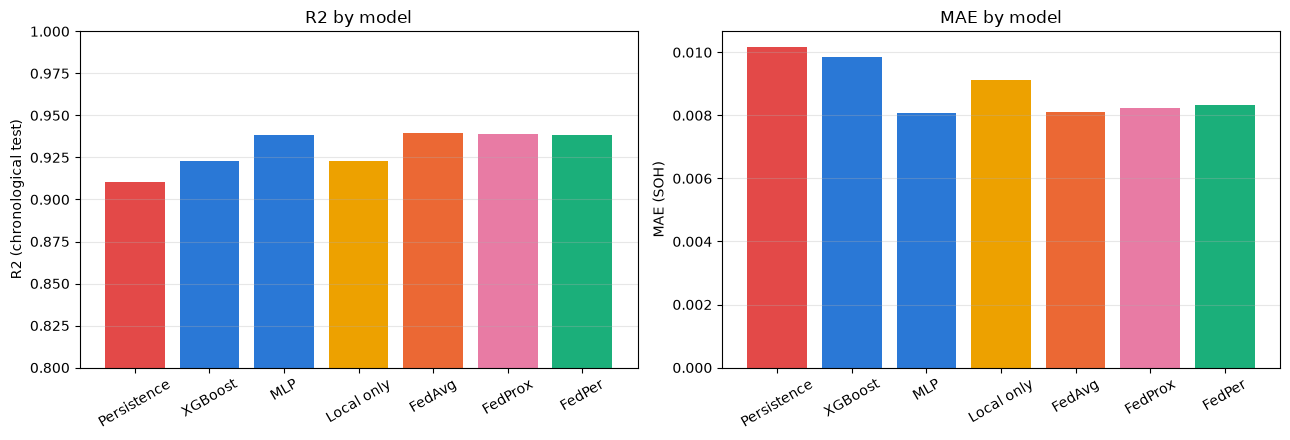

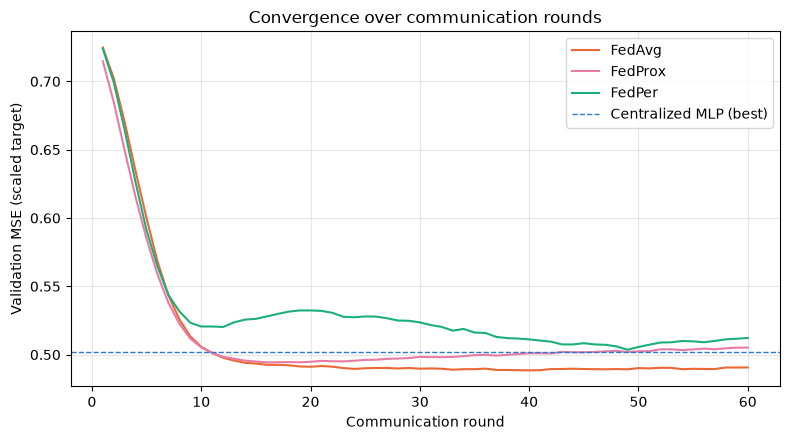

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
colors = [PALETTE[6], PALETTE[0], PALETTE[0], PALETTE[3], PALETTE[1], PALETTE[4], PALETTE[2]]
axes[0].bar(final_table['Model'], final_table['Test R2'], color=colors)
axes[0].set_ylabel('R2 (chronological test)')
axes[0].set_ylim(min(0.8, final_table['Test R2'].min() - 0.02), 1.0)
axes[0].set_title('R2 by model')
axes[1].bar(final_table['Model'], final_table['Test MAE'], color=colors)
axes[1].set_ylabel('MAE (SOH)')
axes[1].set_title('MAE by model')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
for hist, name, color in [(fedavg_history, 'FedAvg', PALETTE[1]),
                          (fedprox_history, 'FedProx', PALETTE[4]),
                          (fedper_history, 'FedPer', PALETTE[2])]:
    ax.plot(hist['round'], hist['val_mse'], color=color, lw=1.5, label=name)
ax.axhline(best_val, color=PALETTE[0], ls='--', lw=1, label='Centralized MLP (best)')
ax.set_xlabel('Communication round')
ax.set_ylabel('Validation MSE (scaled target)')
ax.set_title('Convergence over communication rounds')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Per-battery comparison

The table above pools all test rows. Below, each battery (client) is scored separately on
its own test rows, to see how many batteries each approach helps. MAE is used because R²
is unstable on the few test rows some batteries have.

In [15]:
per_battery_preds = {
    'XGBoost': xgb_model.predict(X_test_processed),
    'MLP': predict_soh(central_mlp, X_test_t, soh_now_test),
    'Local only': local_pred,
    'FedAvg': predict_soh(fedavg_model, X_test_t, soh_now_test),
    'FedProx': predict_soh(fedprox_model, X_test_t, soh_now_test),
    'FedPer': fedper_pred,
}
per_battery = []
for cid in client_ids:
    rows = clients[cid]['test_rows']
    if len(rows) == 0:
        continue
    entry = {'battery_id': cid, 'battery_type': clients[cid]['battery_type'], 'n_test': len(rows)}
    for name, pred in per_battery_preds.items():
        entry[name] = mean_absolute_error(y_test[rows], pred[rows])
    per_battery.append(entry)
per_battery_df = pd.DataFrame(per_battery)

names = list(per_battery_preds)
summary = pd.DataFrame({
    'Median battery MAE': per_battery_df[names].median(),
    'Mean battery MAE': per_battery_df[names].mean(),
    'Worst battery MAE': per_battery_df[names].max(),
})
print(f"Batteries with test rows: {len(per_battery_df)}\n")
print(summary.round(5).to_string())

for other in ['FedAvg', 'FedProx', 'Local only']:
    wins = int((per_battery_df['FedPer'] < per_battery_df[other]).sum())
    print(f"\nFedPer has lower MAE than {other:10s} on {wins}/{len(per_battery_df)} batteries")

print("\nMedian battery MAE by chemistry:")
print(per_battery_df.groupby('battery_type')[names].median().round(5).to_string())

Batteries with test rows: 105

            Median battery MAE  Mean battery MAE  Worst battery MAE
XGBoost                0.01094           0.01370            0.06451
MLP                    0.01373           0.01409            0.07572
Local only             0.01501           0.01636            0.09797
FedAvg                 0.01298           0.01423            0.08468
FedProx                0.01297           0.01431            0.08618
FedPer                 0.01373           0.01492            0.10023

FedPer has lower MAE than FedAvg     on 45/105 batteries

FedPer has lower MAE than FedProx    on 54/105 batteries

FedPer has lower MAE than Local only on 72/105 batteries

Median battery MAE by chemistry:
              XGBoost      MLP  Local only   FedAvg  FedProx   FedPer
battery_type                                                         
LFP           0.00999  0.01547     0.01930  0.01401  0.01457  0.01816
NMC           0.01801  0.01742     0.02110  0.01768  0.01781  0.01694
Unkno

In [16]:
# Collected results, in the same form as the other modules' result tables
os.makedirs('outputs', exist_ok=True)
final_table.to_csv(os.path.join('outputs', 'm3_fl_final_comparison.csv'), index=False)
cold_start_table.to_csv(os.path.join('outputs', 'm3_fl_new_battery_comparison.csv'))
per_battery_df.to_csv(os.path.join('outputs', 'm3_fl_per_battery_mae.csv'), index=False)
pd.concat([fedavg_history.assign(method='FedAvg'), fedprox_history.assign(method='FedProx'),
           fedper_history.assign(method='FedPer')]).to_csv(
    os.path.join('outputs', 'm3_fl_round_history.csv'), index=False)
print("Saved result tables to outputs/")

Saved result tables to outputs/


## 12. Findings

The numbers below are from the run shown in this notebook (one run, fixed seeds). All
models are scored on the same rows.

### 1. Federating the training costs almost nothing

| | Test R² | Test MAE |
|---|---|---|
| Centralized MLP (all data pooled) | 0.938 | 0.0081 |
| FedAvg (no raw data shared) | 0.940 | 0.0081 |
| FedProx | 0.939 | 0.0082 |

The federated network matches the same network trained on pooled data. On this dataset
the batteries can keep their raw cycle data local without losing accuracy.

### 2. Collaboration clearly helps each battery

Training each battery alone ("local only") gives test R² 0.923 and MAE 0.0091, against
0.940 and 0.0081 for FedAvg. The median per-battery MAE also drops from 0.0150 (local
only) to 0.0130 (FedAvg). Many batteries have only a few dozen training cycles (the
smallest has 4), which is far too little to learn degradation on their own.

### 3. Personalization (FedPer) does not add accuracy here

- FedPer reaches test R² 0.938, the same level as FedAvg.
- Per battery, FedPer has lower MAE than FedAvg on only 45 of 105 batteries. It helps
  slightly on NMC cells (median MAE 0.0169 vs. 0.0177) and is worse on LFP cells.
- On new batteries, after a short head fine-tuning on their first half, FedPer (R² 0.969)
  is level with FedAvg (0.969) on the same rows.

A likely reason is that the input features already describe each battery's own state
(recent SOH values, degradation rates, rolling statistics). So a single shared model
already adapts its forecast to each battery, and a personal last layer has little left
to add.

### 4. Federated networks vs. centralized XGBoost

There is no single winner:

- On the pooled chronological test set, the networks (centralized and federated) have a
  higher R² than XGBoost (0.940 vs. 0.923) and a lower MAE.
- XGBoost has the lowest **median per-battery** MAE (0.0109 vs. 0.0130 for FedAvg).
- XGBoost is best on the **unseen batteries** (R² 0.974 vs. 0.964 for FedAvg on all
  1,152 rows).

Note that the networks predict the change in SOH, while XGBoost predicts SOH directly as
in notebook 01. Every model beats the persistence baseline (test R² 0.911).

### 5. Trade-offs

| | Centralized XGBoost | FedAvg / FedProx | FedPer | Local only |
|---|---|---|---|---|
| Accuracy on known batteries | Good | Best pooled R² | Same as FedAvg | Lowest |
| Accuracy on new batteries | Best | Good | Good, after fine-tuning | Not possible |
| Raw data leaves the battery | Yes | No | No | No |
| Data sent per round | none | full network | shared base only | none |

**Conclusion:** for SOH forecasting, federated learning (FedAvg) reaches the accuracy of
centralized training of the same model without sharing raw battery data, and it is much
better than each battery learning alone. Personalization with FedPer brings no clear
extra gain on this data. Centralized XGBoost remains the strongest model for batteries
that were never seen in training.

### Limitations

- One run with fixed seeds. Small differences (in the third decimal) between FedAvg,
  FedProx, FedPer and the centralized MLP are within run-to-run variation.
- The federation is simulated: every client takes part in every round, there are no
  dropouts or delays, and no secure aggregation or differential privacy is applied.
- The feature preprocessing is fitted once on the training rows and shared with all
  clients, as it would be shipped with the initial model.
- The number of rounds and epochs is chosen on validation cycles taken from the end of
  each battery's training data. The test sets are never used for these choices.